In [20]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, ConfusionMatrixDisplay,
    RocCurveDisplay
)
import joblib

RANDOM_STATE = 42
DATA_PATH = "churn_datafile.csv"  # Change this if your CSV is stored elsewhere

## 1. Load the dataset

In [21]:
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)

Dataset shape: (7043, 21)


In [22]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [23]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [24]:
print("Missing values by column:")
df.isnull().sum()

Missing values by column:


customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [25]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


## 2. Data quality checks

In [26]:
print("\nDuplicate rows:", df.duplicated().sum())
print("\nChurn class counts:")
display(df["Churn"].value_counts())
print("\nChurn percentages:")
display((df["Churn"].value_counts(normalize=True) * 100).round(2))


Duplicate rows: 0

Churn class counts:


Churn
No     5174
Yes    1869
Name: count, dtype: int64


Churn percentages:


Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

## 3. Exploratory data analysis (EDA)

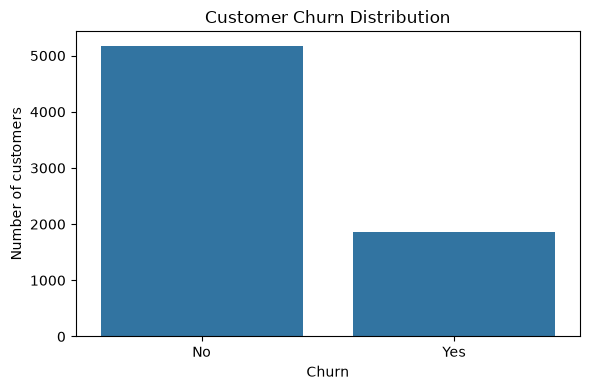

In [27]:
# Target distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of customers")
plt.tight_layout()

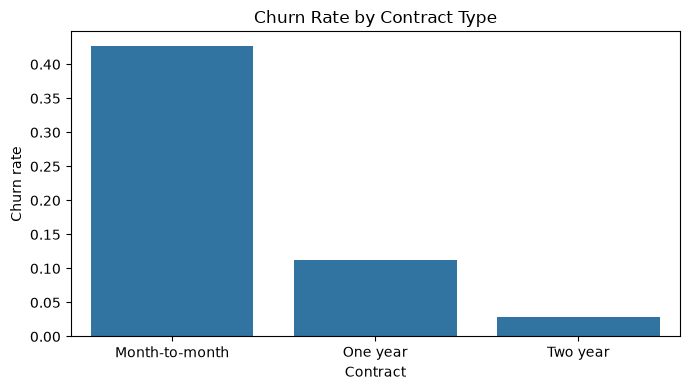

In [28]:
# Churn rate by contract type
plt.figure(figsize=(7, 4))
sns.barplot(data=df, x="Contract", y=df["Churn"].eq("Yes").astype(int), errorbar=None)
plt.title("Churn Rate by Contract Type")
plt.ylabel("Churn rate")
plt.xlabel("Contract")
plt.tight_layout()
plt.show()

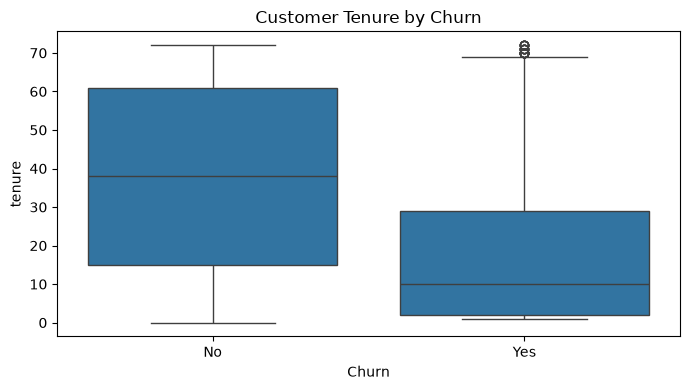

In [29]:
# Tenure by churn
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="Churn", y="tenure")
plt.title("Customer Tenure by Churn")
plt.tight_layout()
plt.show()

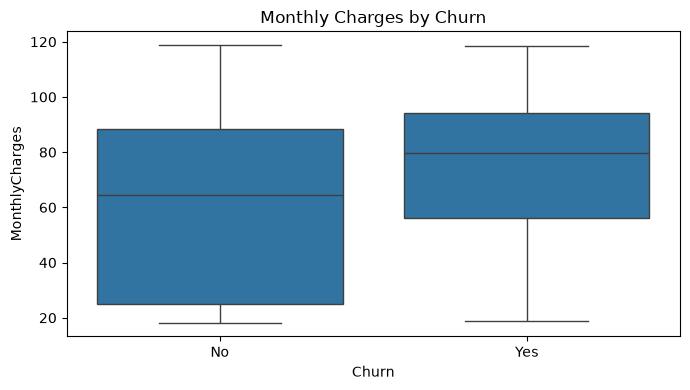

In [30]:
# Monthly charges by churn
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly Charges by Churn")
plt.tight_layout()
plt.show()

## 4. Prepare features and target

In [31]:
data = df.drop(columns=["customerID"]).copy()

data["Churn"] = data["Churn"].astype(str).str.strip()
data = data[data["Churn"].isin(["Yes", "No"])].copy()

X = data.drop(columns=["Churn"])
y = data["Churn"].map({"No": 0, "Yes": 1}) 

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical feature count:", len(categorical_features))
print("Target shape:", y.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical feature count: 15
Target shape: (7043,)
Training rows: 5634
Testing rows: 1409


## 5. Build preprocessing and model pipelines

In [32]:
# Numeric data: fill missing values and scale
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical data: fill missing values and one-hot encode categories
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=2, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1
    )
}

pipelines = {
    name: Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])
    for name, model in models.items()
}

## 6. Train and compare models

In [33]:
results = []
fitted_models = {}

for name, pipeline in pipelines.items():
    pipeline.fit(X_train, y_train)
    fitted_models[name] = pipeline

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).sort_values("ROC-AUC", ascending=False)
display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.7381,0.5043,0.7834,0.6136,0.8413
1,Random Forest,0.7622,0.5394,0.7139,0.6145,0.8355


**Metric guide**
- **Accuracy:** overall proportion of correct predictions.
- **Precision:** of customers predicted to churn, the proportion who actually churn.
- **Recall:** of customers who churn, the proportion detected by the model.
- **F1-score:** balance between precision and recall.
- **ROC-AUC:** ability to rank churners above non-churners across thresholds.

## 7. Evaluate the best model

Selected model (highest test ROC-AUC): Logistic Regression
\nClassification report:
              precision    recall  f1-score   support

    No churn       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



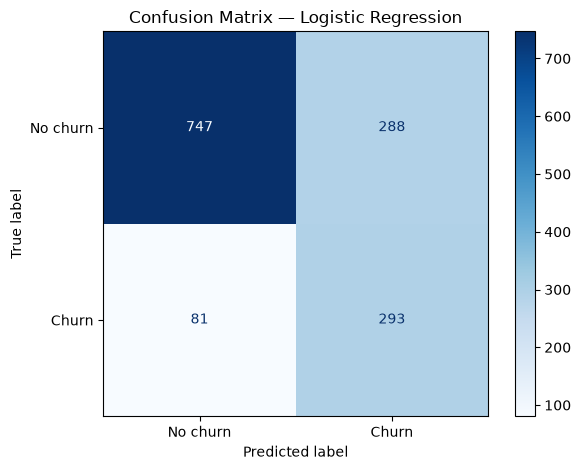

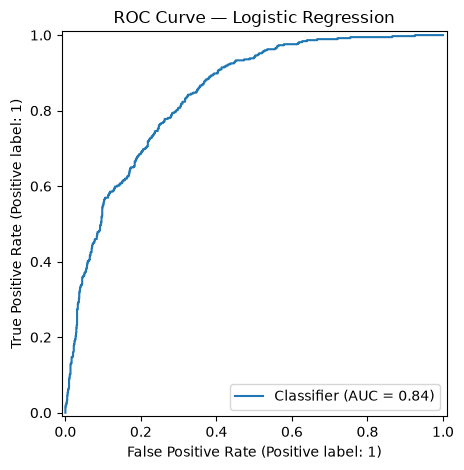

In [34]:
best_model_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_model_name]
best_predictions = best_model.predict(X_test)
best_probabilities = best_model.predict_proba(X_test)[:, 1]

print("Selected model (highest test ROC-AUC):", best_model_name)
print("\\nClassification report:")
print(classification_report(
    y_test, best_predictions, target_names=["No churn", "Churn"], zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, best_predictions, display_labels=["No churn", "Churn"], cmap="Blues"
)
plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

RocCurveDisplay.from_predictions(y_test, best_probabilities)
plt.title(f"ROC Curve — {best_model_name}")
plt.tight_layout()
plt.show()

## 8. Understand important features

,Feature,Absolute coefficient (magnitude)
1,num__tenure,1.123589
38,cat__Contract_Two year,0.781257
16,cat__InternetService_Fiber optic,0.705336
2,num__MonthlyCharges,0.663581
36,cat__Contract_Month-to-month,0.663399
15,cat__InternetService_DSL,0.621009
3,num__TotalCharges,0.457211
35,cat__StreamingMovies_Yes,0.274978
34,cat__StreamingMovies_No internet service,0.274568
31,cat__StreamingTV_No internet service,0.274568


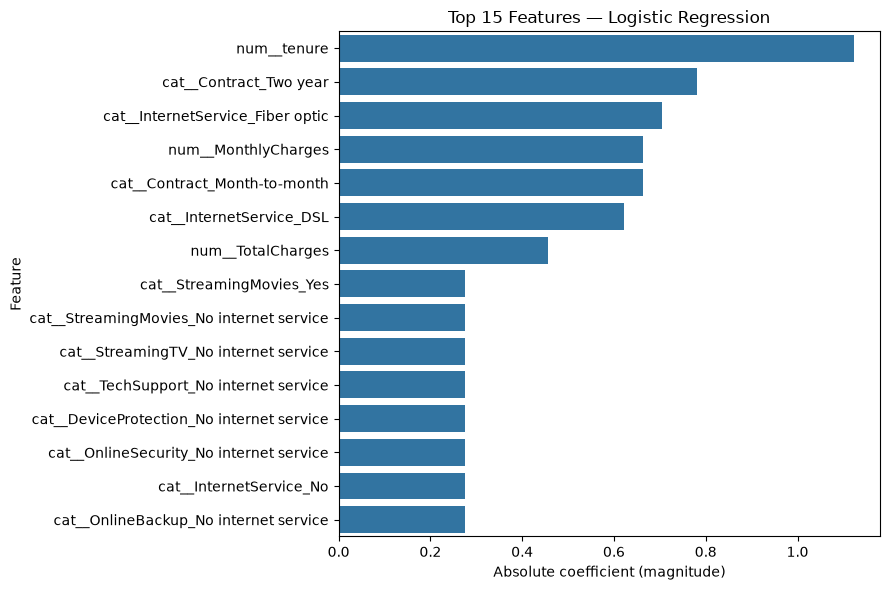

In [35]:
# Extract transformed feature names and classifier coefficients/importances
fitted_preprocessor = best_model.named_steps["preprocessor"]
classifier = best_model.named_steps["classifier"]
feature_names = fitted_preprocessor.get_feature_names_out()

if hasattr(classifier, "feature_importances_"):
    importance_values = classifier.feature_importances_
    importance_label = "Feature importance"
elif hasattr(classifier, "coef_"):
    importance_values = np.abs(classifier.coef_[0])
    importance_label = "Absolute coefficient (magnitude)"
else:
    importance_values = None

if importance_values is not None:
    importance_df = pd.DataFrame({
        "Feature": feature_names,
        importance_label: importance_values
    }).sort_values(importance_label, ascending=False).head(15)

    display(importance_df)
    plt.figure(figsize=(9, 6))
    sns.barplot(data=importance_df, x=importance_label, y="Feature")
    plt.title(f"Top 15 Features — {best_model_name}")
    plt.tight_layout()
    plt.show()
else:
    print("This classifier does not expose built-in feature importance.")

## 9. Predict churn for a customer

In [36]:
example_customer = X_test.iloc[[0]]
predicted_class = best_model.predict(example_customer)[0]
churn_probability = best_model.predict_proba(example_customer)[0, 1]

print("Predicted churn:", "Yes" if predicted_class == 1 else "No")
print(f"Estimated churn probability: {churn_probability:.1%}")
display(example_customer)

Predicted churn: No
Estimated churn probability: 11.5%


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
437,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),114.05,8468.2


## 10. Save the trained model

In [37]:
MODEL_PATH = "customer_churn_model.joblib"
joblib.dump(best_model, MODEL_PATH)
print(f"Saved model to: {MODEL_PATH}")

Saved model to: customer_churn_model.joblib
